# Workshop 3 – Stats for AI (Bloque 2)
## Componentes de una serie de tiempo y el modelo de Caminata Aleatoria (Random Walk)

**Alumno:** Manuel Bajos

Este notebook tiene dos partes:

1. **Réplica del workshop**: el código del workshop con mis notas explicando cada paso.
2. **Challenge**: el mismo análisis aplicado a **Walmart de México (WALMEX.MX)**.

# Parte 1. Réplica del workshop

## 1. ¿Qué es una serie de tiempo?

Una **serie de tiempo** mide una variable de un mismo sujeto a intervalos regulares (diario, mensual, trimestral). A diferencia de un dataset de corte transversal, **el orden importa**: si revuelvo las filas destruyo la información. Por eso en series de tiempo no se puede hacer un *train/test split* aleatorio; se separa por fecha (entrenamos con el pasado y probamos con el futuro).

Componentes de una serie:

| Componente | Qué es | ¿Predecible? |
|---|---|---|
| **Tendencia** | Movimiento persistente hacia arriba o abajo | Sí, relativamente fácil |
| **Estacionalidad** | Patrón que se repite cada año / semana / día | Sí, relativamente fácil |
| **Ciclos** | Subidas y bajadas de más de un año sin periodo fijo | Difícil |
| **Irregular** | Choques idiosincráticos, media cero | No, por definición |

## 1.1 Descomponer una serie real

Descargo un dataset mensual con las ventas en volumen (toneladas) de varias marcas de una categoría de producto de consumo. El servidor rechaza peticiones que no parecen venir de un navegador, por eso se manda un `User-Agent`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from io import BytesIO

url = "http://www.apradie.com/ec2004/salesbrands3.xlsx"
# Algunos servidores rechazan peticiones que no parecen de un navegador:
headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0 Safari/537.36'}
response = requests.get(url, headers=headers)
response.raise_for_status()
sales_brand = pd.read_excel(BytesIO(response.content), sheet_name='Resultado')

Convierto la columna `date` a tipo fecha y la pongo como índice. Con `asfreq('MS')` le digo a pandas que es una serie **mensual** cuyas fechas son el primer día de cada mes (*Month Start*). Esto es importante porque la descomposición necesita saber la frecuencia de la serie.

In [2]:
sales_brand['date'] = pd.to_datetime(sales_brand['date'])
sales_brand = sales_brand.set_index('date').sort_index().asfreq('MS')
sales_brand.head()

,qbrand1tons,salesbrand1,qbrand2tons,salesbrand2,qbrand3tons,salesbrand3,qbrand4tons,salesbrand4,qbrand5tons,salesbrand5,qbrand6tons,salesbrand6,tonstotal,salestotal
date,,,,,,,,,,,,,,
2015-01-01,106.62,60780.72,195.46,60700.51,293.10,75196.35,185.91,48228.51,28.94,2295.50,338.38,55561.26,1148.41,302762.85
2015-02-01,105.82,60411.47,216.09,68289.15,494.46,105010.90,149.30,39922.14,24.66,1973.43,284.52,51469.74,1274.85,327076.83
2015-03-01,88.82,53174.89,220.15,62529.54,356.88,90902.84,144.65,39788.22,23.75,1903.24,251.34,50395.48,1085.59,298694.21
2015-04-01,86.69,50861.69,170.74,50575.68,291.07,72853.34,161.43,42692.59,21.00,1684.28,230.29,49124.61,961.22,267792.19
2015-05-01,87.23,51014.23,177.17,54327.48,318.09,75277.10,141.09,37167.52,23.44,1883.41,250.45,46906.63,997.47,266576.37


Grafico las ventas en volumen de la marca 6 para ver visualmente qué componentes tiene.

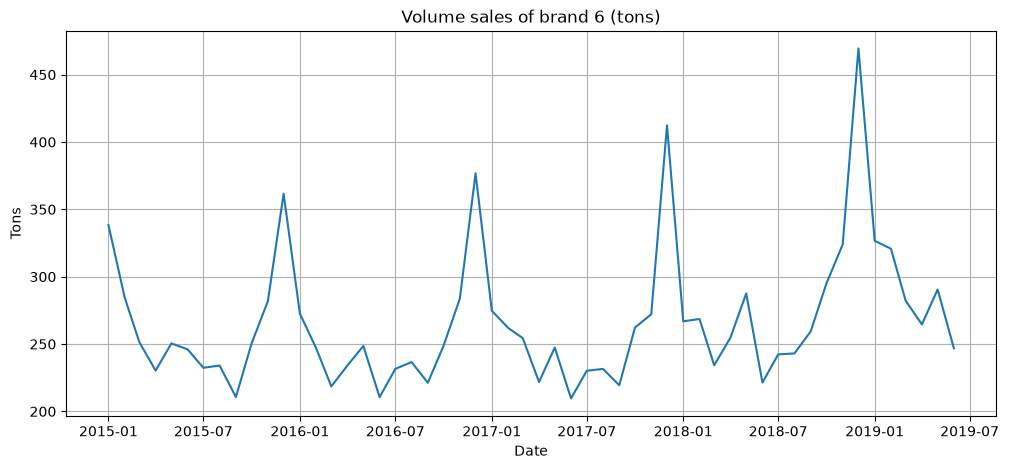

In [3]:
plt.figure(figsize=(12, 5))
plt.plot(sales_brand.index, sales_brand['qbrand6tons'])
plt.title('Volume sales of brand 6 (tons)')
plt.xlabel('Date')
plt.ylabel('Tons')
plt.grid(True)
plt.show()

Se ve una **tendencia creciente** y un **patrón que se repite cada año**. Para separar los componentes uso **STL** (*Seasonal-Trend decomposition using LOESS*):

- La aplico al **logaritmo** de las ventas. Con logs, un efecto estacional que es un *porcentaje* del nivel (p. ej. "diciembre vende 20% más") se vuelve un efecto **aditivo constante**, que es lo que STL supone.
- `period=12` porque el patrón se repite cada 12 meses.
- `robust=True` hace que los valores atípicos no distorsionen la tendencia ni la estacionalidad (se van al residual).

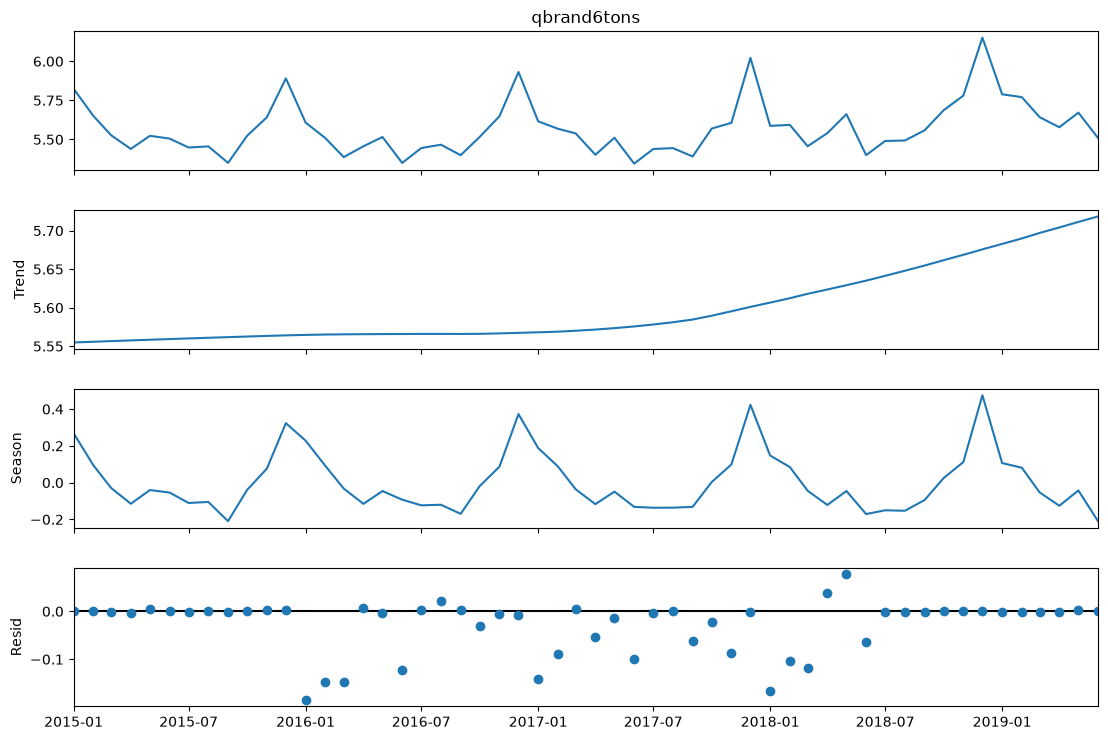

In [4]:
from statsmodels.tsa.seasonal import STL

log_q6 = np.log(sales_brand['qbrand6tons'])
stl_q6 = STL(log_q6, period=12, robust=True).fit()

fig = stl_q6.plot()
fig.set_size_inches(12, 8)
plt.show()

STL escribe la serie como **tendencia + estacional + residual**:

- **Trend**: la dirección de largo plazo (si hubiera ciclos, aparecerían aquí como ondas lentas).
- **Season**: el patrón que se repite cada 12 meses.
- **Resid**: el componente irregular, lo que sobra después de quitar tendencia y estacionalidad.

**¿Qué tan fuertes son la tendencia y la estacionalidad?** (Hyndman y Athanasopoulos, 2021). Se compara la varianza del residual contra la varianza del componente + residual:

$$F_{trend} = \max\left(0,\ 1-\frac{Var(R_t)}{Var(T_t+R_t)}\right) \qquad F_{seasonal} = \max\left(0,\ 1-\frac{Var(R_t)}{Var(S_t+R_t)}\right)$$

Si el residual es pequeño comparado con el componente, $F$ se acerca a 1 (componente fuerte); si el residual domina, $F$ se acerca a 0.

In [5]:
R = stl_q6.resid
F_trend = max(0, 1 - R.var() / (stl_q6.trend + R).var())
F_seas = max(0, 1 - R.var() / (stl_q6.seasonal + R).var())
print(f"Strength of trend:       {F_trend:.3f}")
print(f"Strength of seasonality: {F_seas:.3f}")

Strength of trend:       0.523
Strength of seasonality: 0.875


**Interpretación:** para la marca 6 la fuerza de la tendencia es ≈ 0.52 (moderada) y la de la estacionalidad ≈ 0.88 (muy fuerte). Es decir, gran parte del movimiento de esta serie se explica por el patrón anual, que es fácil de pronosticar.

El componente irregular es lo que hace que cualquier serie sea parcialmente impredecible. El modelo más simple donde **todo, excepto una deriva constante, es irregular** es la caminata aleatoria.

## 2. El modelo de Caminata Aleatoria (Random Walk)

### 2.1 El modelo
La hipótesis de caminata aleatoria en finanzas (Fama, 1965) dice que el **logaritmo** del precio de una acción se comporta como una caminata aleatoria con deriva. Si $Y_t$ es el log-precio del día $t$:

$$Y_t = \phi_0 + Y_{t-1} + \varepsilon_t, \qquad \varepsilon_t \sim N(0, \sigma_\varepsilon^2) \text{ independientes en el tiempo}$$

- $\varepsilon_t$: el **choque** del día, el efecto neto de todas las noticias de ese día.
- $\phi_0$: la **deriva** (*drift*). Si $\phi_0>0$ la serie tiende a crecer; si $\phi_0=0$ es una caminata aleatoria sin deriva.
- $\sigma_\varepsilon$: la **volatilidad** del choque.

### 2.2 ¿Qué es predecible y qué no?
Pasando $Y_{t-1}$ a la izquierda:

$$\underbrace{Y_t - Y_{t-1}}_{r_t \text{ (log-rendimiento)}} = \phi_0 + \varepsilon_t$$

- El **cambio** (el rendimiento) es impredecible más allá de su media $\phi_0$: los rendimientos pasados no ayudan a predecir el de mañana.
- El **nivel** sí tiene un mejor pronóstico: $E[Y_{t+1}\mid Y_t] = Y_t + \phi_0$ (el "pronóstico ingenuo" o *naive forecast*).
- Lo que no podemos saber es **qué tan lejos** de ese pronóstico va a caer el valor real, y esa incertidumbre crece con el horizonte.

### 2.3 El valor después de N periodos
Sustituyendo hacia atrás:

$$Y_N = Y_0 + N\phi_0 + \sum_{t=1}^{N}\varepsilon_t$$

Si pudiéramos "re-correr la historia" muchas veces desde el mismo $Y_0$:

- $E[Y_N\mid Y_0] = Y_0 + N\phi_0$ (los choques tienen media cero).
- $Var(Y_N\mid Y_0) = N\sigma_\varepsilon^2 \Rightarrow SD(Y_N\mid Y_0) = \sqrt{N}\,\sigma_\varepsilon$ (choques independientes con la misma varianza).

Esta es la **regla de la raíz del tiempo**: la incertidumbre crece con $\sqrt{N}$, no con $N$. A un año (≈252 días) la incertidumbre es $\sqrt{252}\approx 15.9$ veces la de un día, no 252 veces.

> **Cuidado:** $Var(Y_N)=N\sigma^2_\varepsilon$ es la varianza **entre muchas historias posibles**. Solo observamos una historia; la desviación estándar de los log-precios observados **a lo largo del tiempo** es otra cosa y, como la caminata aleatoria no es estacionaria, no converge a nada con sentido.

### 2.4 Estimar los parámetros correctamente
De $r_t = \phi_0 + \varepsilon_t$:

- $\hat\phi_0$ = **media** de los log-rendimientos diarios.
- $\hat\sigma_\varepsilon$ = **desviación estándar** de los log-rendimientos diarios.

Con $N$ precios hay $N-1$ rendimientos y la suma es telescópica:
$$\hat\phi_0=\frac{1}{N-1}\sum_{t=2}^{N}(Y_t-Y_{t-1})=\frac{Y_N-Y_1}{N-1}$$

## 3. El S&P 500 como caminata aleatoria

### 3.1 Datos
Descargo el S&P 500 diario de Yahoo Finance. `auto_adjust=True` ajusta los precios por dividendos y splits; `.squeeze()` convierte el DataFrame de una columna en una Serie y `.dropna()` quita días sin dato.

In [6]:
import yfinance as yf

sp500 = yf.download("^GSPC", start="2008-01-01", end="2026-09-30",
                    auto_adjust=True, progress=False)['Close'].squeeze().dropna()
sp500.name = 'SP500'
sp500.tail()

Date
2026-09-23    7706.029785
2026-09-24    7704.129883
2026-09-25    7743.410156
2026-09-28    7683.689941
2026-09-29    7670.839844
Name: SP500, dtype: float64

Separo los datos como en un ejercicio real de pronóstico:

- **Entrenamiento (2008–2025):** para estimar el modelo.
- **Prueba (2026):** para revisar el pronóstico con datos que el modelo nunca vio.

Trabajo con el **logaritmo** del precio, y los log-rendimientos diarios son su primera diferencia (`diff()`). El primer rendimiento es `NaN` porque no hay día anterior, por eso `dropna()`.

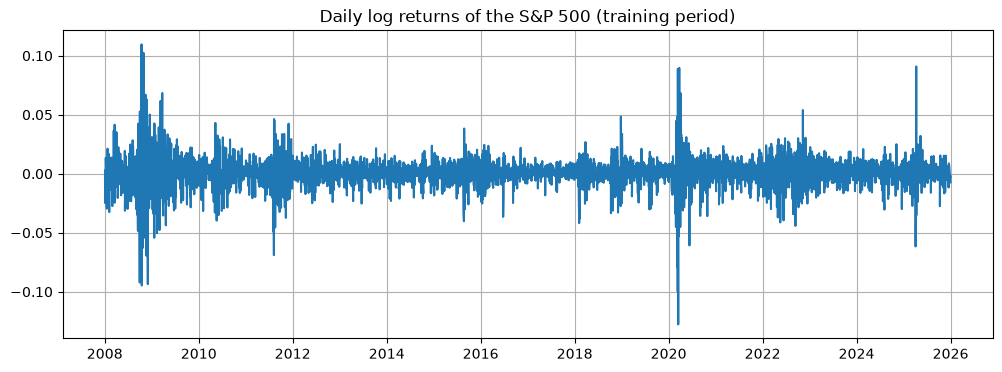

In [7]:
lnsp = np.log(sp500)
ln_train = lnsp[:'2025-12-31']
ln_test = lnsp['2026-01-01':]

r_train = ln_train.diff().dropna()   # daily log returns

plt.figure(figsize=(12, 4))
plt.plot(r_train.index, r_train)
plt.title('Daily log returns of the S&P 500 (training period)')
plt.grid(True)
plt.show()

El log-precio tiene tendencia, pero los **rendimientos** fluctúan alrededor de una media constante cercana a cero. También se ve **agrupamiento de volatilidad** (2008–2009, 2020): periodos tranquilos y periodos turbulentos. La caminata aleatoria básica supone $\sigma_\varepsilon$ constante y no captura esto (los modelos GARCH sí).

### 3.2 ¿Los rendimientos se pueden predecir con rendimientos pasados?
Si la hipótesis de caminata aleatoria se cumple, el rendimiento de hoy no debería estar correlacionado con el de ayer. La correlación de una serie con su propio valor pasado es la **autocorrelación**:

In [8]:
ac1 = float(r_train.autocorr(lag=1))
ac1

-0.12093156811865384

La autocorrelación de orden 1 es ≈ −0.12, cercana a cero: el rendimiento de ayer casi no dice nada del de hoy, consistente con la caminata aleatoria (un $\rho$ de −0.12 explica solo $\rho^2 \approx 1.5\%$ de la varianza).

### 3.3 Estimación de los parámetros
Estimo $\phi_0$ con la media de los rendimientos y $\sigma_\varepsilon$ con su desviación estándar, y compruebo la fórmula telescópica (último log-precio − primero)/(número de rendimientos).

In [9]:
phi0 = float(r_train.mean())
sigma = float(r_train.std())
y0 = float(ln_train.iloc[0])
N = len(ln_train)

# Check: the mean of returns equals (last - first)/(number of returns)
phi0_check = float((ln_train.iloc[-1] - ln_train.iloc[0]) / (N - 1))
print(f"phi0  = {phi0:.6f}   (check: {phi0_check:.6f})")
print(f"sigma = {sigma:.6f}")
print(f"Annual drift      = 252*phi0       = {252*phi0:.2%}")
print(f"Annual volatility = sqrt(252)*sigma = {np.sqrt(252)*sigma:.2%}")

phi0  = 0.000343   (check: 0.000343)
sigma = 0.012658
Annual drift      = 252*phi0       = 8.65%
Annual volatility = sqrt(252)*sigma = 20.09%


Las dos formas de calcular la deriva coinciden. La deriva diaria es ≈ 0.0003 y la volatilidad diaria ≈ 0.0127. Anualizando (252 días hábiles): deriva ≈ 8.6% y volatilidad ≈ 20.1%. La deriva se multiplica por 252 (las medias se suman) y la volatilidad por $\sqrt{252}$ (las **varianzas** se suman, no las desviaciones).

### 3.4 Simular una trayectoria
Simulo una caminata aleatoria que empieza en el primer log-precio del periodo de entrenamiento. Primero con un ciclo `for` que sigue la ecuación literalmente. `default_rng(1)` fija la semilla para que el resultado sea reproducible.

In [10]:
rng = np.random.default_rng(1)
shocks = rng.normal(0, sigma, N)

rw1 = np.zeros(N)
rw1[0] = y0
for t in range(1, N):
    rw1[t] = phi0 + rw1[t-1] + shocks[t]

In [11]:
len(rw1)

4529

Lo mismo sin ciclo: como $Y_t = Y_0 + t\phi_0 + \sum_{s=1}^{t}\varepsilon_s$, basta con la **suma acumulada** (`np.cumsum`) de deriva + choques. El paso del día 0 se pone en cero para que la trayectoria empiece exactamente en $Y_0$. La versión vectorizada es mucho más rápida y es la que usaremos para Monte Carlo.

In [12]:
steps = phi0 + shocks
steps[0] = 0                          # no shock on day 0
rw1_vec = y0 + np.cumsum(steps)
print(np.allclose(rw1, rw1_vec))      # both methods give the same path

True


También simulo una caminata **sin deriva** ($\phi_0=0$) usando **los mismos choques**, para aislar el efecto de la deriva:

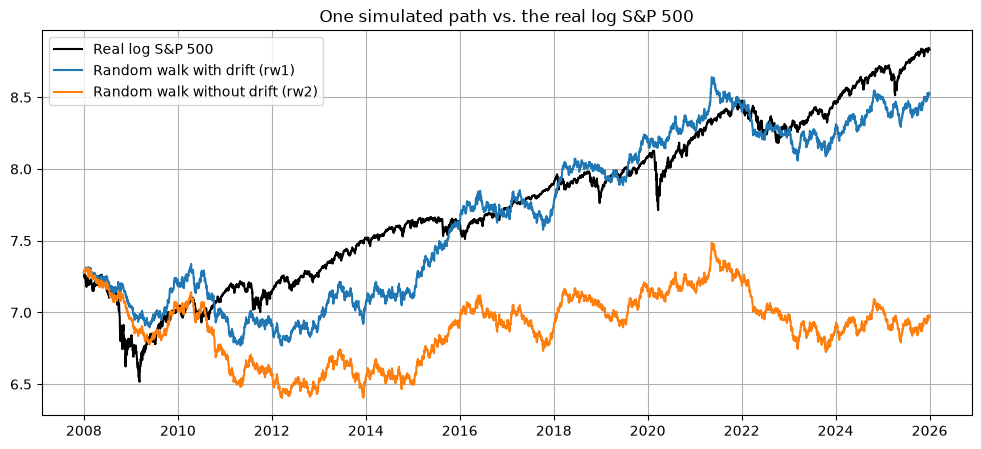

In [13]:
steps0 = shocks.copy()
steps0[0] = 0
rw2 = y0 + np.cumsum(steps0)

plt.figure(figsize=(12, 5))
plt.plot(ln_train.index, ln_train, color='black', label='Real log S&P 500')
plt.plot(ln_train.index, rw1, label='Random walk with drift (rw1)')
plt.plot(ln_train.index, rw2, label='Random walk without drift (rw2)')
plt.title('One simulated path vs. the real log S&P 500')
plt.legend()
plt.grid(True)
plt.show()

La diferencia entre `rw1` y `rw2` es exactamente la recta $t\cdot\phi_0$: con los mismos choques, la deriva "empuja" la trayectoria hacia arriba. Pero **una sola trayectoria no dice mucho**: si cambio la semilla, cambia por completo. Para saber qué dice realmente el modelo necesito muchas trayectorias: una **simulación Monte Carlo**.

### 3.5 Simulación Monte Carlo: muchas trayectorias
Simulo 1,000 trayectorias de todo el periodo de entrenamiento en una matriz: cada **fila** es una historia posible y cada **columna** un día. `cumsum(axis=1)` acumula a lo largo de los días de cada fila.

In [14]:
n_paths = 1000
rng = np.random.default_rng(123)
step_matrix = phi0 + rng.normal(0, sigma, size=(n_paths, N))
step_matrix[:, 0] = 0                          # day 0 = y0 for every path
paths = y0 + np.cumsum(step_matrix, axis=1)    # one path per row

Para cada día calculo los percentiles 5, 50 y 95 **entre las 1,000 trayectorias** (`axis=0`, por columna). Eso da un **fan chart**: la banda donde el modelo espera que esté la serie el 90% del tiempo.

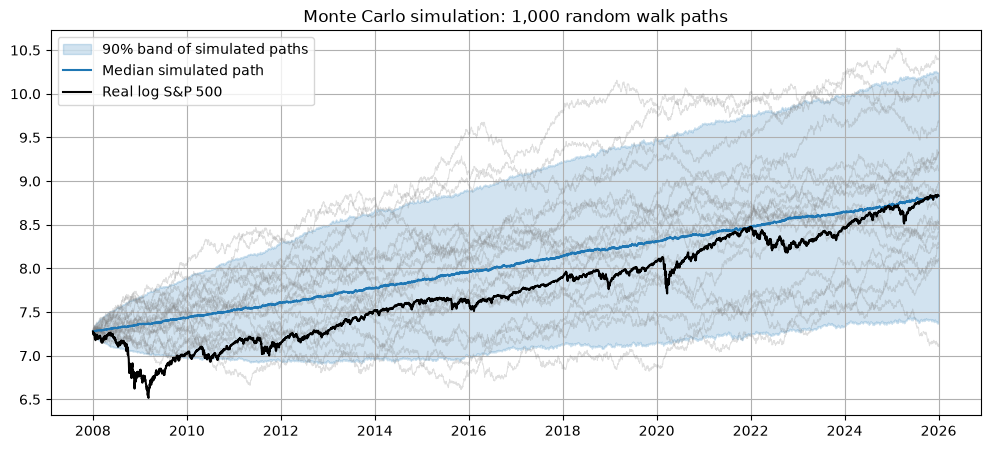

In [15]:
p05, p50, p95 = np.percentile(paths, [5, 50, 95], axis=0)

plt.figure(figsize=(12, 5))
for i in range(20):
    plt.plot(ln_train.index, paths[i], color='grey', alpha=0.25, linewidth=0.7)
plt.fill_between(ln_train.index, p05, p95, color='tab:blue', alpha=0.2, label='90% band of simulated paths')
plt.plot(ln_train.index, p50, color='tab:blue', label='Median simulated path')
plt.plot(ln_train.index, ln_train, color='black', label='Real log S&P 500')
plt.title('Monte Carlo simulation: 1,000 random walk paths')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

In [16]:
inside = float(np.mean((ln_train.values >= p05) & (ln_train.values <= p95)))
print(f"Share of days the real S&P 500 is inside the 90% band: {inside:.1%}")

Share of days the real S&P 500 is inside the 90% band: 93.4%


El S&P 500 real se queda dentro de la banda del 90% la gran mayoría de los días: **la serie real parece una trayectoria más de la caminata aleatoria**.

### 3.6 La regla de la raíz del tiempo, visualmente
La banda se abre con el tiempo. Comparo la desviación estándar **entre trayectorias** de cada día con el valor teórico $\sigma_\varepsilon\sqrt{t}$:

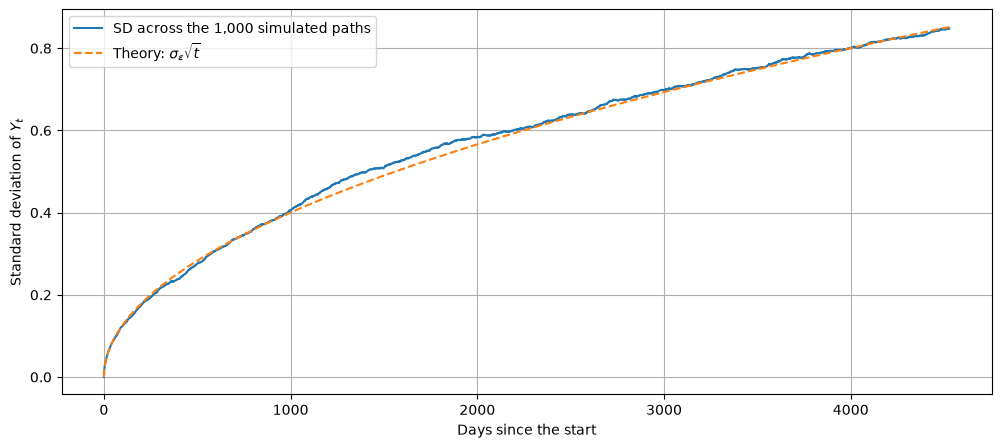

In [17]:
t_idx = np.arange(N)
sd_across = paths.std(axis=0)

plt.figure(figsize=(12, 5))
plt.plot(t_idx, sd_across, label='SD across the 1,000 simulated paths')
plt.plot(t_idx, sigma * np.sqrt(t_idx), '--', label=r'Theory: $\sigma_\varepsilon\sqrt{t}$')
plt.xlabel('Days since the start')
plt.ylabel('Standard deviation of $Y_t$')
plt.legend()
plt.grid(True)
plt.show()

Las curvas simulada y teórica se enciman: es $Var(Y_N)=N\sigma_\varepsilon^2$ en una gráfica. La curva es cóncava (crece cada vez más lento) porque crece con $\sqrt{t}$.

## 4. Pronosticar con la caminata aleatoria
Parado en el último día de 2025, ¿qué dice el modelo sobre 2026? Analíticamente, a $h$ días:

$$Y_{T+h} \mid Y_T \sim N\left(Y_T + h\phi_0,\ h\sigma_\varepsilon^2\right)$$

También lo obtengo por Monte Carlo (5,000 trayectorias de $h$ días que empiezan en $Y_T$), que es el método que sigue funcionando con modelos más complejos donde no hay fórmula cerrada. Los percentiles se calculan en log y se pasan a precio con `exp`; como `exp` es creciente, el percentil del log es el log del percentil del precio.

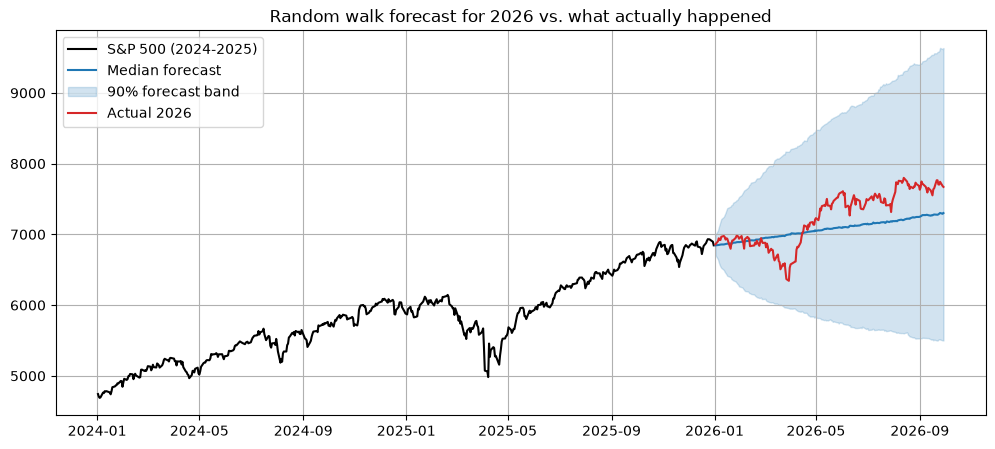

In [18]:
yT = float(ln_train.iloc[-1])
h = len(ln_test)

rng = np.random.default_rng(2026)
fc_paths = yT + np.cumsum(phi0 + rng.normal(0, sigma, size=(5000, h)), axis=1)
f05, f50, f95 = np.percentile(fc_paths, [5, 50, 95], axis=0)

plt.figure(figsize=(12, 5))
plt.plot(sp500['2024-01-01':'2025-12-31'], color='black', label='S&P 500 (2024-2025)')
plt.plot(ln_test.index, np.exp(f50), color='tab:blue', label='Median forecast')
plt.fill_between(ln_test.index, np.exp(f05), np.exp(f95), color='tab:blue', alpha=0.2, label='90% forecast band')
plt.plot(sp500['2026-01-01':], color='tab:red', label='Actual 2026')
plt.title('Random walk forecast for 2026 vs. what actually happened')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

Respondo preguntas concretas con la simulación y comparo con la fórmula analítica:

$$P(Y_{T+h} > Y_T) = P\left(Z > \frac{-h\phi_0}{\sigma_\varepsilon\sqrt{h}}\right) = \Phi\left(\frac{h\phi_0}{\sigma_\varepsilon\sqrt{h}}\right)$$

*(Nota: en el material original algunas etiquetas dicen "end-2025", pero el valor que se evalúa es el **último día del periodo de prueba, 29-sep-2026**; corregí las etiquetas.)*

In [19]:
from scipy.stats import norm

end_sim = fc_paths[:, -1]
actual_end = float(ln_test.iloc[-1])

p_up_mc = float(np.mean(end_sim > yT))
p_up_theory = float(norm.cdf(h * phi0 / (sigma * np.sqrt(h))))
band_low, band_high = np.exp(np.percentile(end_sim, [5, 95]))
pct_actual = float(np.mean(end_sim < actual_end))

print(f"Trading days in the forecast: {h}")
print(f"P(S&P ends the test period above its end-2025 level): MC = {p_up_mc:.3f}, theory = {p_up_theory:.3f}")
print(f"90% band for {ln_test.index[-1].date()}: {band_low:,.0f} to {band_high:,.0f}")
print(f"Actual level on {ln_test.index[-1].date()}: {np.exp(actual_end):,.0f}  (percentile within the simulation: {pct_actual:.2f})")

Trading days in the forecast: 186
P(S&P ends the test period above its end-2025 level): MC = 0.642, theory = 0.644
90% band for 2026-09-29: 5,500 to 9,634
Actual level on 2026-09-29: 7,671  (percentile within the simulation: 0.61)


**Interpretación:**

- El modelo da una probabilidad de ≈ 0.64 de que el S&P 500 termine el periodo arriba de su nivel de cierre de 2025. Es mayor a 0.5 por la deriva positiva, pero está lejos de ser seguro. Monte Carlo y la fórmula coinciden.
- La banda del 90% es muy ancha (≈ 5,500 a 9,600 puntos): esa es la incertidumbre real del modelo.
- El valor real cayó en el percentil ≈ 0.61 de la distribución simulada: un resultado "normal" para el modelo.

**Discusión:** cualquier modelo de IA que diga pronosticar precios tiene que **superar fuera de muestra** a este benchmark ingenuo.

## 5. Lo que sigue: ¿y si el coeficiente de $Y_{t-1}$ no es 1?
$$Y_t = \phi_0 + \phi_1 Y_{t-1} + \varepsilon_t$$
Con $\phi_1 \neq 1$ tenemos un modelo **AR(1)**, y el valor de $\phi_1$ cambia por completo el comportamiento de la serie. Es el punto de partida del Workshop 4.

---
# Parte 2. CHALLENGE – Walmart de México (WALMEX.MX)

Elegí **Walmart de México (WALMEX.MX)**. Descargo precios diarios del 2015-01-01 al 2026-09-30 y uso:

- **Entrenamiento:** 2015–2025 (para estimar $\phi_0$ y $\sigma_\varepsilon$).
- **Prueba:** 2026-01-01 a 2026-09-29 (último dato disponible), para evaluar el pronóstico.

> **Nota sobre el enunciado:** las preguntas del pronóstico dicen "end-2025 above its end-2024 level" y "actual end-2025 price", pero el pronóstico que se pide es **para 2026 partiendo del último precio de 2025**. Lo interpreto como en el ejemplo del S&P 500 del workshop: **¿termina el periodo de prueba (29-sep-2026) arriba del cierre de 2025?** y **¿en qué percentil cayó el precio real del 29-sep-2026?** Al final del punto 2 también evalúo el año 2025 para cubrir la lectura literal.

## 1. Datos y estimación

### 1.0 Descarga y revisión de los datos
Uso precios de cierre ajustados (`auto_adjust=True`) para que los dividendos de WALMEX no aparezcan como caídas falsas del precio. Reviso que no haya fechas duplicadas ni datos faltantes.

Observaciones: 2952  |  de 2015-01-02 a 2026-09-29
Fechas duplicadas: 0  |  Valores faltantes: 0


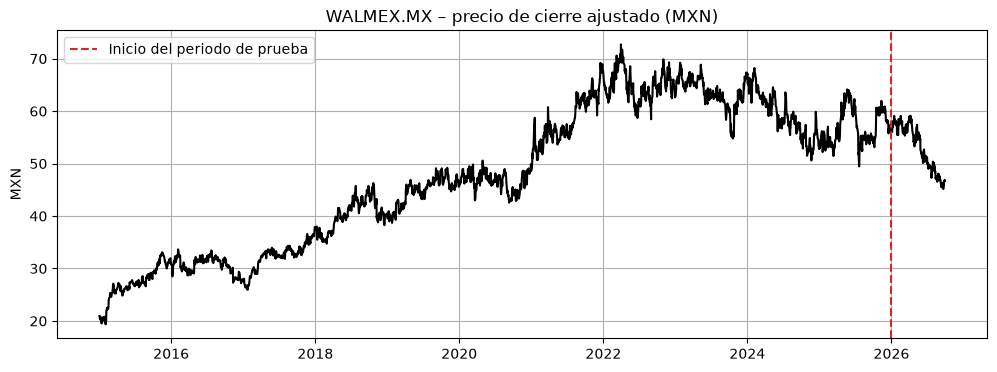

In [20]:
wal = yf.download("WALMEX.MX", start="2015-01-01", end="2026-09-30",
                  auto_adjust=True, progress=False)['Close'].squeeze().dropna()
wal.name = 'WALMEX'

print(f"Observaciones: {len(wal)}  |  de {wal.index[0].date()} a {wal.index[-1].date()}")
print(f"Fechas duplicadas: {wal.index.duplicated().sum()}  |  Valores faltantes: {wal.isna().sum()}")

plt.figure(figsize=(12, 4))
plt.plot(wal.index, wal, color='black')
plt.axvline(pd.Timestamp('2026-01-01'), color='tab:red', linestyle='--', label='Inicio del periodo de prueba')
plt.title('WALMEX.MX – precio de cierre ajustado (MXN)')
plt.ylabel('MXN')
plt.legend()
plt.grid(True)
plt.show()

### 1.1 Log-precios, separación train/test y log-rendimientos

Precios de entrenamiento: 2766  ->  rendimientos: 2765
Días en el periodo de prueba: 186


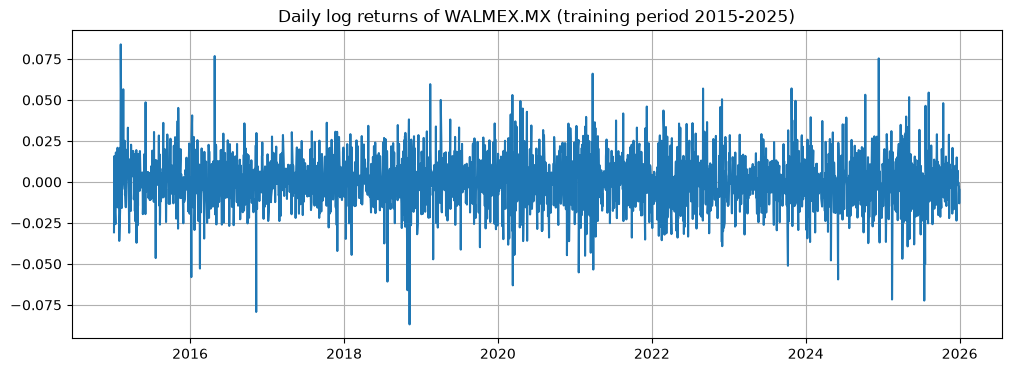

In [21]:
lnw = np.log(wal)
lnw_train = lnw[:'2025-12-31']
lnw_test = lnw['2026-01-01':]

rw_train = lnw_train.diff().dropna()     # log-rendimientos diarios (entrenamiento)

print(f"Precios de entrenamiento: {len(lnw_train)}  ->  rendimientos: {len(rw_train)}")
print(f"Días en el periodo de prueba: {len(lnw_test)}")

plt.figure(figsize=(12, 4))
plt.plot(rw_train.index, rw_train)
plt.title('Daily log returns of WALMEX.MX (training period 2015-2025)')
plt.grid(True)
plt.show()

Igual que el S&P 500, los rendimientos de WALMEX oscilan alrededor de una media cercana a cero y muestran **agrupamiento de volatilidad**: rachas más turbulentas en 2015–2016 (incluida la elección de EE.UU. en nov-2016), noviembre de 2018 (propuesta de eliminar comisiones bancarias que golpeó a toda la BMV), 2020–2021 (COVID) y 2024–2025, separadas por periodos más tranquilos como 2017 o 2022–2023. Esto ya avisa que el supuesto de $\sigma_\varepsilon$ constante es una simplificación.

### 1.2 Estimar $\phi_0$ y $\sigma_\varepsilon$ y anualizarlos
- $\hat\phi_0$ = media de los log-rendimientos; anual: $252\,\hat\phi_0$.
- $\hat\sigma_\varepsilon$ = desviación estándar de los log-rendimientos; anual: $\sqrt{252}\,\hat\sigma_\varepsilon$.

In [22]:
phi0_w = float(rw_train.mean())
sigma_w = float(rw_train.std())
y0_w = float(lnw_train.iloc[0])
N_w = len(lnw_train)

phi0_w_check = float((lnw_train.iloc[-1] - lnw_train.iloc[0]) / (N_w - 1))

phi0_w_annual = 252 * phi0_w
sigma_w_annual = np.sqrt(252) * sigma_w

print(f"phi0 diaria  = {phi0_w:.6f}   (check telescópico: {phi0_w_check:.6f})")
print(f"sigma diaria = {sigma_w:.6f}")
print()
print(f"Deriva anual (log)          = 252 * phi0      = {phi0_w_annual:.4f}  ->  {phi0_w_annual:.2%}")
print(f"Equivalente simple anual    = exp(252*phi0)-1 = {np.exp(phi0_w_annual)-1:.2%}")
print(f"Volatilidad anual           = sqrt(252)*sigma = {sigma_w_annual:.4f}  ->  {sigma_w_annual:.2%}")
print()
print(f"Comparación S&P 500: deriva anual {252*phi0:.2%}, volatilidad anual {np.sqrt(252)*sigma:.2%}")

phi0 diaria  = 0.000356   (check telescópico: 0.000356)
sigma diaria = 0.015946

Deriva anual (log)          = 252 * phi0      = 0.0897  ->  8.97%
Equivalente simple anual    = exp(252*phi0)-1 = 9.39%
Volatilidad anual           = sqrt(252)*sigma = 0.2531  ->  25.31%

Comparación S&P 500: deriva anual 8.65%, volatilidad anual 20.09%


**Interpretación:**

- La deriva diaria es $\hat\phi_0 \approx 0.00036$ y la volatilidad diaria $\hat\sigma_\varepsilon \approx 0.0159$. La comprobación telescópica da exactamente el mismo valor de $\phi_0$.
- **En términos anuales**: deriva ≈ **9.0%** en log-rendimiento (≈ 9.4% simple) y volatilidad ≈ **25.3%**.
- Comparado con el S&P 500, WALMEX tuvo una deriva parecida (≈ 9% vs ≈ 8.6%) pero **más volatilidad** (≈ 25% vs ≈ 20%). Tiene sentido: es una sola empresa (riesgo idiosincrático no diversificado) y cotiza en pesos, así que también absorbe choques del mercado mexicano.
- Lo más importante: la deriva diaria es **minúscula comparada con la volatilidad diaria** ($\sigma/\phi_0 \approx 45$). En un día, el ruido domina por completo a la tendencia.

### 1.3 Autocorrelación de orden 1
Si la caminata aleatoria se cumple, $\rho_1 \approx 0$. Para juzgar si es "cercana a cero" uso:

- La banda aproximada de significancia al 95% para una autocorrelación bajo ruido blanco: $\pm 2/\sqrt{n}$.
- La prueba de **Ljung-Box** (H0: no hay autocorrelación).
- $\rho_1^2$: la proporción de la varianza del rendimiento de hoy que se explicaría con el de ayer.

In [23]:
from statsmodels.stats.diagnostic import acorr_ljungbox

ac1_w = float(rw_train.autocorr(lag=1))
n_r = len(rw_train)
bound = 2 / np.sqrt(n_r)
lb = acorr_ljungbox(rw_train, lags=[1])

print(f"Autocorrelación lag-1:            {ac1_w:.4f}")
print(f"Banda 95% aprox. (+/- 2/sqrt(n)):  +/-{bound:.4f}   (n = {n_r})")
print(f"Ljung-Box (lag 1): Q = {lb['lb_stat'].iloc[0]:.2f},  p-value = {lb['lb_pvalue'].iloc[0]:.5f}")
print(f"R^2 implícito (rho^2):            {ac1_w**2:.2%}")

Autocorrelación lag-1:            -0.0757
Banda 95% aprox. (+/- 2/sqrt(n)):  +/-0.0380   (n = 2765)
Ljung-Box (lag 1): Q = 15.84,  p-value = 0.00007
R^2 implícito (rho^2):            0.57%


**Interpretación:**

- La autocorrelación de orden 1 es $\rho_1 \approx -0.076$: **muy cercana a cero** en magnitud.
- Estadísticamente **sí es distinta de cero**: queda fuera de la banda $\pm 0.038$ y Ljung-Box rechaza H0 (p ≈ 0.0001). Con casi 2,800 observaciones, hasta una correlación pequeñísima resulta significativa.
- Económicamente es irrelevante: $\rho_1^2 \approx 0.6\%$, es decir, el rendimiento de ayer explica **menos del 1%** de la variación del de hoy. Además es negativa, lo típico de efectos de microestructura (rebote entre precio de compra y venta, pequeñas sobre-reacciones que se corrigen al día siguiente), y explotarla probablemente no cubriría los costos de transacción.

**Conclusión:** el resultado es **consistente, en la práctica, con la hipótesis de caminata aleatoria**. Hay una desviación estadística pequeña, pero los rendimientos pasados prácticamente no ayudan a predecir el rendimiento de mañana. (Si $\rho_1$ fuera algo como 0.3, la hipótesis sí se rechazaría con fuerza: el pasado explicaría ~9% de la varianza).

## 2. Pronóstico Monte Carlo para 2026

Simulo **5,000 trayectorias** (más de las 2,000 que pide el challenge) que empiezan en el **último log-precio de 2025**. Simulo **252 días** hacia adelante:

- Los primeros $h$ días (los del periodo de prueba, hasta el 29-sep-2026) se usan para el fan chart y las probabilidades.
- Los 252 días completos se usan en el punto 3 (raíz del tiempo), que pide la desviación estándar a 21 y a 252 días.

Cada día simulado: $Y_{t} = \phi_0 + Y_{t-1} + \varepsilon_t$, con $\varepsilon_t \sim N(0, \hat\sigma^2_\varepsilon)$.

In [24]:
yT_w = float(lnw_train.iloc[-1])           # último log-precio de 2025
h_w = len(lnw_test)                        # días hábiles del periodo de prueba
H = 252                                    # horizonte total simulado (1 año)
n_sim = 5000

rng = np.random.default_rng(2026)
fc_w = yT_w + np.cumsum(phi0_w + rng.normal(0, sigma_w, size=(n_sim, H)), axis=1)

fc_w_test = fc_w[:, :h_w]                  # sólo los días que coinciden con 2026
w05, w50, w95 = np.percentile(fc_w_test, [5, 50, 95], axis=0)

print(f"Matriz simulada: {fc_w.shape}  (trayectorias x días)")
print(f"Precio de cierre 2025 (punto de partida): {np.exp(yT_w):.2f} MXN  ({lnw_train.index[-1].date()})")

Matriz simulada: (5000, 252)  (trayectorias x días)
Precio de cierre 2025 (punto de partida): 56.01 MXN  (2025-12-31)


### 2.1 Fan chart en escala de precio
Grafico los percentiles 5, 50 y 95 (convertidos a precio con `exp`), los precios reales de **2025** (lo que el modelo "vio" justo antes de pronosticar) y los precios reales de **2026** (lo que realmente pasó).

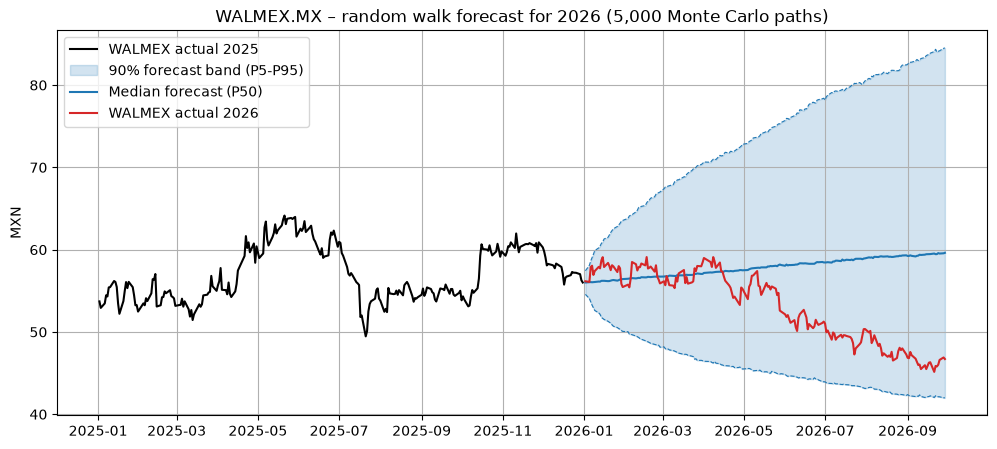

Días de 2026 en que el precio real quedó dentro de la banda del 90%: 100.0%


In [25]:
plt.figure(figsize=(12, 5))
plt.plot(wal['2025-01-01':'2025-12-31'], color='black', label='WALMEX actual 2025')
plt.fill_between(lnw_test.index, np.exp(w05), np.exp(w95), color='tab:blue', alpha=0.2,
                 label='90% forecast band (P5-P95)')
plt.plot(lnw_test.index, np.exp(w50), color='tab:blue', label='Median forecast (P50)')
plt.plot(lnw_test.index, np.exp(w05), color='tab:blue', linewidth=0.8, linestyle='--')
plt.plot(lnw_test.index, np.exp(w95), color='tab:blue', linewidth=0.8, linestyle='--')
plt.plot(wal['2026-01-01':], color='tab:red', label='WALMEX actual 2026')
plt.title(f'WALMEX.MX – random walk forecast for 2026 ({n_sim:,} Monte Carlo paths)')
plt.ylabel('MXN')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

inside_w = float(np.mean((lnw_test.values >= w05) & (lnw_test.values <= w95)))
print(f"Días de 2026 en que el precio real quedó dentro de la banda del 90%: {inside_w:.1%}")

**Interpretación:** la banda se abre como un abanico porque la incertidumbre crece con $\sqrt{h}$. La mediana sube ligeramente por la deriva positiva. En 2026 el precio real de WALMEX **cayó** y siguió cerca de la mediana hasta abril y después se fue a la mitad inferior del abanico, acercándose al percentil 5 hacia septiembre; aun así **se mantuvo dentro de la banda del 90% todos los días** del periodo de prueba.

### 2.2 Probabilidad de terminar arriba del cierre de 2025: Monte Carlo vs fórmula
Con Monte Carlo cuento la proporción de trayectorias que terminan (29-sep-2026, día $h$) arriba de $Y_T$. Analíticamente:

$$P(Y_{T+h} > Y_T) = \Phi\left(\frac{h\,\phi_0}{\sigma_\varepsilon\sqrt{h}}\right) = \Phi\left(\sqrt{h}\,\frac{\phi_0}{\sigma_\varepsilon}\right)$$

In [26]:
end_w = fc_w[:, h_w - 1]                   # log-precio simulado el último día de prueba
actual_end_w = float(lnw_test.iloc[-1])

p_up_mc_w = float(np.mean(end_w > yT_w))
z_w = h_w * phi0_w / (sigma_w * np.sqrt(h_w))
p_up_theory_w = float(norm.cdf(z_w))
se_mc = np.sqrt(p_up_mc_w * (1 - p_up_mc_w) / n_sim)   # error estándar de la proporción MC

print(f"Horizonte: h = {h_w} días hábiles (hasta {lnw_test.index[-1].date()})")
print(f"P(WALMEX termina arriba del cierre 2025):")
print(f"   Monte Carlo = {p_up_mc_w:.3f}   (error estándar MC ~ {se_mc:.3f})")
print(f"   Analítica   = {p_up_theory_w:.3f}   (z = {z_w:.3f})")

Horizonte: h = 186 días hábiles (hasta 2026-09-29)
P(WALMEX termina arriba del cierre 2025):
   Monte Carlo = 0.611   (error estándar MC ~ 0.007)
   Analítica   = 0.620   (z = 0.305)


**Interpretación:**

- Ambos métodos dan una probabilidad de ≈ **0.61–0.62** de que WALMEX termine el periodo de prueba arriba de su cierre de 2025.
- **Sí coinciden**: la diferencia (≈ 0.008) es del orden de 1.5 errores estándar de Monte Carlo, o sea, es solo ruido de simulación. Con más trayectorias se acercarían todavía más. Deben coincidir porque la simulación usa exactamente el modelo normal del que sale la fórmula.
- La probabilidad es mayor a 0.5 por la deriva positiva, pero está muy lejos de ser segura: con $h=186$ días, la deriva acumulada ($h\phi_0 \approx 0.066$) es apenas un tercio de la incertidumbre acumulada ($\sigma\sqrt{h} \approx 0.217$).

### 2.3 ¿En qué percentil cayó el precio real?

In [27]:
pct_actual_w = float(np.mean(end_w < actual_end_w))
band_low_w, band_med_w, band_high_w = np.exp(np.percentile(end_w, [5, 50, 95]))
ret_test = np.exp(actual_end_w - yT_w) - 1

# percentil analítico
z_actual = (actual_end_w - (yT_w + h_w * phi0_w)) / (sigma_w * np.sqrt(h_w))

print(f"Cierre 2025:                 {np.exp(yT_w):.2f} MXN")
print(f"Precio real {lnw_test.index[-1].date()}:     {np.exp(actual_end_w):.2f} MXN   (rendimiento: {ret_test:.1%})")
print(f"Banda 90% simulada:          {band_low_w:.2f} a {band_high_w:.2f} MXN   (mediana {band_med_w:.2f})")
print(f"Percentil del precio real:   Monte Carlo = {pct_actual_w:.3f}   |   analítico = {norm.cdf(z_actual):.3f}  (z = {z_actual:.2f})")

Cierre 2025:                 56.01 MXN
Precio real 2026-09-29:     46.71 MXN   (rendimiento: -16.6%)
Banda 90% simulada:          41.99 a 84.52 MXN   (mediana 59.62)
Percentil del precio real:   Monte Carlo = 0.130   |   analítico = 0.127  (z = -1.14)


**Interpretación:**

- WALMEX cerró 2025 en ≈ 56.0 MXN y el 29-sep-2026 estaba en ≈ 46.7 MXN: una caída de ≈ **−16.6%**.
- El precio real cayó en el **percentil ≈ 0.13** de la distribución simulada (z ≈ −1.1). Es decir, solo ≈ 13% de las trayectorias simuladas terminaron más abajo.
- **¿Fue un periodo "inusual"?** Según el modelo, **no**. Fue un resultado malo, del lado bajo de la distribución, pero queda **dentro de la banda del 90%** (≈ 42.0 a 84.5 MXN). Un resultado que ocurre con probabilidad ~13% pasa aproximadamente uno de cada ocho años; no es un evento extremo. Sería "inusual" si hubiera caído por debajo del percentil 5 (o arriba del 95).
- Esto también muestra lo poco informativo que es el pronóstico puntual: la mediana decía ≈ 59.6 MXN y el precio real terminó ~13 pesos abajo, sin que el modelo esté "equivocado".

**Lectura literal del enunciado (año 2025 completo).** Para cubrir también la redacción "end-2025 vs end-2024", evalúo 2025 con el mismo modelo, parado al cierre de 2024 y mirando 252 días adelante (con la fórmula analítica):

In [28]:
y_end24 = float(lnw[:'2024-12-31'].iloc[-1])
y_end25 = yT_w
h25 = len(lnw['2025-01-01':'2025-12-31'])

p_up_2025 = norm.cdf(h25 * phi0_w / (sigma_w * np.sqrt(h25)))
z_2025 = (y_end25 - (y_end24 + h25 * phi0_w)) / (sigma_w * np.sqrt(h25))

print(f"Cierre 2024: {np.exp(y_end24):.2f}  |  Cierre 2025: {np.exp(y_end25):.2f}  |  rendimiento 2025: {np.exp(y_end25 - y_end24) - 1:.1%}")
print(f"P(terminar 2025 arriba del cierre 2024) según el modelo: {p_up_2025:.3f}")
print(f"Percentil del cierre real de 2025: {norm.cdf(z_2025):.3f}  (z = {z_2025:.2f})")

Cierre 2024: 53.35  |  Cierre 2025: 56.01  |  rendimiento 2025: 5.0%
P(terminar 2025 arriba del cierre 2024) según el modelo: 0.638
Percentil del cierre real de 2025: 0.436  (z = -0.16)


Para 2025: el modelo daba ≈ 0.64 de probabilidad de terminar arriba del cierre de 2024, y efectivamente WALMEX subió ≈ 5%. Ese cierre cae alrededor del **percentil 0.44**, muy cerca de la mediana: **2025 fue un año completamente normal** para el modelo. (Ojo: 2025 es parte del periodo de entrenamiento, así que esta no es una evaluación fuera de muestra; la evaluación honesta es la de 2026.)

## 3. Raíz del tiempo
Con la simulación de 252 días calculo la desviación estándar del log-precio simulado a **21 días** (≈ 1 mes) y a **252 días** (≈ 1 año) y comparo su razón con $\sqrt{252/21}=\sqrt{12}$.

SD simulada a 21 días:   0.0728   (teoría sigma*sqrt(21)  = 0.0731)
SD simulada a 252 días:  0.2499   (teoría sigma*sqrt(252) = 0.2531)
Razón SD252 / SD21:      3.435
sqrt(252/21) = sqrt(12): 3.464
Razón de varianzas:      11.80   (vs 252/21 = 12)


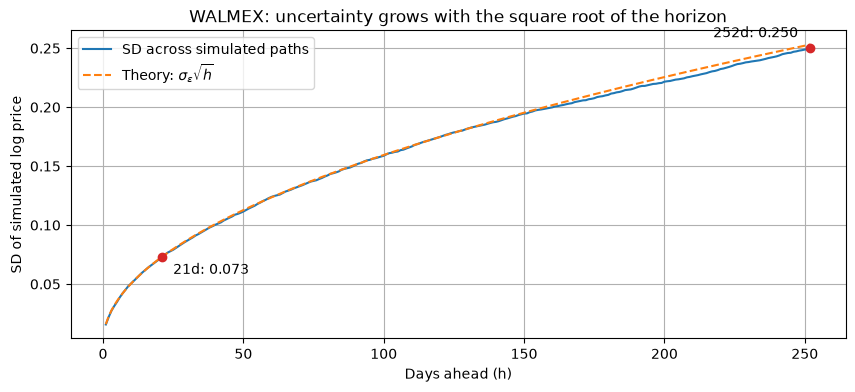

In [29]:
sd_21 = float(fc_w[:, 21 - 1].std())       # columna 20 = día 21 adelante
sd_252 = float(fc_w[:, 252 - 1].std())     # columna 251 = día 252 adelante
ratio = sd_252 / sd_21

print(f"SD simulada a 21 días:   {sd_21:.4f}   (teoría sigma*sqrt(21)  = {sigma_w*np.sqrt(21):.4f})")
print(f"SD simulada a 252 días:  {sd_252:.4f}   (teoría sigma*sqrt(252) = {sigma_w*np.sqrt(252):.4f})")
print(f"Razón SD252 / SD21:      {ratio:.3f}")
print(f"sqrt(252/21) = sqrt(12): {np.sqrt(252/21):.3f}")
print(f"Razón de varianzas:      {(sd_252/sd_21)**2:.2f}   (vs 252/21 = {252/21:.0f})")

# Gráfica: SD entre trayectorias vs horizonte
hh = np.arange(1, H + 1)
plt.figure(figsize=(10, 4))
plt.plot(hh, fc_w.std(axis=0), label='SD across simulated paths')
plt.plot(hh, sigma_w * np.sqrt(hh), '--', label=r'Theory: $\sigma_\varepsilon\sqrt{h}$')
plt.scatter([21, 252], [sd_21, sd_252], color='tab:red', zorder=3)
plt.annotate(f'21d: {sd_21:.3f}', (21, sd_21), textcoords='offset points', xytext=(8, -12))
plt.annotate(f'252d: {sd_252:.3f}', (252, sd_252), textcoords='offset points', xytext=(-70, 8))
plt.xlabel('Days ahead (h)')
plt.ylabel('SD of simulated log price')
plt.title('WALMEX: uncertainty grows with the square root of the horizon')
plt.legend()
plt.grid(True)
plt.show()

**Interpretación:**

- SD a 21 días ≈ **0.073** (≈ 7.3% en log-precio) y a 252 días ≈ **0.250** (≈ 25%). Ambas coinciden con $\sigma_\varepsilon\sqrt{h}$.
- La razón es ≈ **3.43**, prácticamente igual a $\sqrt{12} \approx 3.46$ (la pequeña diferencia es error de simulación).

**¿Por qué la razón no es 12?** Porque lo que se suma en el tiempo son las **varianzas**, no las desviaciones estándar. El log-precio a $h$ días es $Y_T + h\phi_0 + \sum_{t=1}^{h}\varepsilon_t$; como los choques son independientes, $Var = h\,\sigma^2_\varepsilon$. Entonces la **varianza** a 252 días sí es 12 veces la de 21 días, pero la **desviación estándar** crece con la raíz: $\sqrt{12}\approx 3.46$. Sería 12 solo si los choques estuvieran perfectamente correlacionados (si todos los días se movieran en la misma dirección); como son independientes, parte de los choques positivos se cancela con los negativos.

## 4. Reflexión

Los rendimientos diarios de WALMEX casi no tienen memoria ($\rho_1\approx-0.08$, explica <1% de la varianza) y la deriva diaria es ~45 veces menor que la volatilidad diaria. Por eso, el mejor pronóstico del precio de mañana es prácticamente **el precio de hoy** (más una deriva minúscula): ese es el benchmark ingenuo. Un modelo de IA que pronostica "el precio de mañana" puede verse muy preciso (un $R^2$ altísimo en niveles), solo porque copia el precio de hoy; eso no es habilidad. Lo que importa es predecir el **cambio** (el rendimiento), y ahí casi todo es ruido. Además, la incertidumbre crece con $\sqrt{h}$: en 2026 la banda del 90% iba de ~42 a ~85 MXN y el precio cayó al percentil 13 sin que el modelo fallara. Para ser útil, un modelo de IA tendría que **superar a la caminata aleatoria fuera de muestra** (error menor en datos que no vio, con validación ordenada en el tiempo, sin fugas de información), acertar la dirección de forma consistente por encima del ~50%, dar bandas de incertidumbre bien calibradas, y que esa ventaja sobreviva a los costos de transacción y a cambios de régimen de volatilidad.